# Pair 2: Destination video generation

**Name: Arnob Deb, Student ID: 60841338.**

A travel platform wants short destination clips from a text description. This notebook compares two
open text-to-video models and it runs locally through ComfyUI on the same 5 prompts and 2 seeds.

Model Used: 

Platform A: Wan 2.1 T2V-1.3B. Platform B: Wan 2.2 TI2V-5B

How to use it: Keep this notebook next to the workflows and results folders and run every cell
from top to bottom. With every switch in the Settings cell set to False, it uses the saved clips and
scores, needs no GPU or ComfyUI, and takes under a minute. The switches repeat each step:

Switch (What it does and What it needs): 

RUN_GENERATION: Makes any missing clips. It needs ComfyUI open with both Wan models and an NVIDIA GPU
RUN_SCORING: Rescores every clip with CLIP and jitter. It needs internet to download CLIP
RUN_DEMO: Makes a new clip per model from DEMO_PROMPT. It needs ComfyUI to be open.


## Setup

This installs the extra packages that this pair needs.

In [1]:
%pip install psutil imageio imageio-ffmpeg av transformers pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import copy, csv, json, random, shutil, subprocess, threading, time
import urllib.error, urllib.parse, urllib.request
from pathlib import Path

import imageio.v3 as iio
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import torch
from IPython.display import Video, display
from PIL import Image

RUN_GENERATION = False  # True: make any missing clips through ComfyUI.
RUN_SCORING = False     # True: score every clip again.
RUN_DEMO = False        # True: make a new demo clip per model. False shows the saved ones.
DEMO_PROMPT = "A wide shot of a quiet harbour at sunset, small boats, gentle waves"
MODELS = ["wan22", "wan21"]

try:
    HERE = Path(__vsc_ipynb_file__).parent
except NameError:
    HERE = Path.cwd()
RESULTS = HERE / "results"
print(f"Using the files in {HERE}")

Using the files in d:\LEKAPORA\3rd Semester\COMP8410 Advanced Topics in Artificial Intelligence\Assignment 1\pair2_destination_video


## 1. Prompts and workflows

Each prompt tests a known difficulty for video models. The same prompts and seeds go to both models, so
each makes 10 clips. The workflows in workflows are ComfyUI's built-in templates saved with
Export (API). So each model keeps the sampling settings its authors recommend. Only the prompt, seed
and file name change between clips. All clips are 832 x 480 and about 5 seconds long: 121 frames at
24 fps for Wan 2.2 and 81 frames at 16 fps for Wan 2.1.

In [3]:
SEEDS = [11, 22]
PROMPTS = [  
    ("harbour", "Aerial drone shot at golden hour over a sparkling harbour, white sails of a famous opera house and a large steel arch bridge, ferries crossing the water, warm sunset light, travel film, smooth camera movement", "A recognisable real landmark"),
    ("reef", "Underwater shot of a colourful coral reef with schools of tropical fish, clear blue water and rays of sunlight, a snorkeller gently swimming past, travel film, slow graceful movement", "Many small moving objects"),
    ("laneway", "A narrow city laneway on a rainy evening, cafe tables under awnings, street art on brick walls, wet pavement reflecting warm lights, people walking with umbrellas, slow forward tracking shot, travel film", "People and reflections"),
    ("desert", "A vast red desert landscape at dawn with a huge sandstone rock formation on the horizon, sky changing from purple to orange, slow wide panning shot, peaceful and respectful, travel film", "Slow, large-scale motion and changing light"),
    ("mountain", "Snow-capped mountains above a calm alpine lake, a small wooden jetty in the foreground, clouds drifting slowly, crisp morning light, gentle camera push-in, travel film", "Fine detail in a mostly still scene"),
]
TEXT = {pid: text for pid, text, _ in PROMPTS}

WORKFLOWS = {name: json.loads((HERE / "workflows" / f"{name}.json").read_text()) for name in MODELS}
WORKFLOWS["wan21"]["40"]["inputs"].update(width=832, height=480, length=81)

## 2. Generating clips through ComfyUI

For each clip the code fills the prompt into the node feeding the sampler's positive input and sets every
seed. Then sends the workflow to ComfyUI, waits, downloads the video and records the time and the peak GPU
memory and RAM of the whole PC. Each model finishes all its clips before the next starts. So model
loading is counted once and the median time is the fairer speed measure.

In [4]:
def comfyui():
    for port in (8000, 8188):
        try:
            urllib.request.urlopen(f"http://127.0.0.1:{port}/system_stats", timeout=5)
            return f"http://127.0.0.1:{port}"
        except OSError:
            pass
    raise SystemExit("Can't reach ComfyUI. Open it, then run this cell again.")


def get(url):
    return json.loads(urllib.request.urlopen(url, timeout=60).read())


def fill(workflow, text, seed, label):
    """Copy the workflow and set this clip's prompt, seeds and file name."""
    filled = copy.deepcopy(workflow)
    
    link = next(n["inputs"]["positive"] for n in workflow.values() if "positive" in n.get("inputs", {}))
    while not isinstance(workflow[str(link[0])]["inputs"].get("text"), str):
        link = next(v for v in workflow[str(link[0])]["inputs"].values() if isinstance(v, list))
    filled[str(link[0])]["inputs"]["text"] = text
    for node in filled.values():
        for key in ("seed", "noise_seed"):
            if isinstance(node["inputs"].get(key), (int, float)):
                node["inputs"][key] = seed
        if "filename_prefix" in node["inputs"]:
            node["inputs"]["filename_prefix"] = f"pair2/{label}"
    return filled


def watch_memory(peaks, stop):
    while not stop.wait(2):
        peaks["ram"] = max(peaks["ram"], psutil.virtual_memory().used / 1024**3)
        out = subprocess.run(["nvidia-smi", "--query-gpu=memory.used", "--format=csv,noheader,nounits"], capture_output=True, text=True).stdout
        try:
            peaks["gpu"] = max(peaks["gpu"], float(out.split()[0]))
        except (ValueError, IndexError):
            pass  


def make_clip(server, model, prompt_id, text, seed, folder):
    label = f"{model}_{prompt_id}_{seed}"
    row = {"model": model, "prompt": prompt_id, "seed": seed, "status": "failed", "error": ""}
    print(f"Generating {label}")
    peaks, stop = {"gpu": 0.0, "ram": 0.0}, threading.Event()
    watcher = threading.Thread(target=watch_memory, args=(peaks, stop), daemon=True)
    watcher.start()
    started = time.perf_counter()
    try:
        body = json.dumps({"prompt": fill(WORKFLOWS[model], text, seed, label)}).encode()
        pid = json.loads(urllib.request.urlopen(urllib.request.Request(f"{server}/prompt", body, {"Content-Type": "application/json"}), timeout=60).read())["prompt_id"]
        while not (entry := get(f"{server}/history/{pid}").get(pid)) or not (entry["status"]["completed"] or entry["status"].get("status_str") == "error"):
            if time.perf_counter() - started > 3600:
                raise TimeoutError("ComfyUI didn't finish within an hour")
            time.sleep(5)
        videos = [item for out in entry["outputs"].values() for items in out.values() if isinstance(items, list)
                  for item in items if isinstance(item, dict) and str(item.get("filename", "")).lower().endswith((".mp4", ".webm", ".mov", ".gif", ".webp"))]
        if entry["status"].get("status_str") == "error":  # For example, running out of GPU memory.
            row["error"] = next((str(d.get("exception_message", "")).strip()[:300] for kind, d in entry["status"].get("messages", []) if kind == "execution_error"), "Unknown error")
        elif videos:
            query = urllib.parse.urlencode({key: videos[0].get(key, "") for key in ("filename", "subfolder", "type")})
            with urllib.request.urlopen(f"{server}/view?{query}", timeout=300) as response, (folder / f"{label}.mp4").open("wb") as file:
                shutil.copyfileobj(response, file)
            row.update(status="done", file=f"{label}.mp4")
        else:
            row["error"] = "ComfyUI finished without a video"
    except urllib.error.HTTPError as problem:  # ComfyUI rejected the workflow, for example a missing model file.
        row["error"] = problem.read().decode(errors="replace")[:300]
    except (OSError, TimeoutError) as problem:
        row["error"] = str(problem)[:300]
    row["seconds"] = round(time.perf_counter() - started, 1)
    stop.set()
    watcher.join()
    row.update(peak_gpu_gb=round(peaks["gpu"] / 1024, 2), peak_ram_gb=round(peaks["ram"], 1))
    print(f"  {row['status']} in {row['seconds']} s {row['error']}")
    return row

In [5]:
if RUN_GENERATION:
    server, clips, table = comfyui(), RESULTS / "clips", RESULTS / "generation.csv"
    clips.mkdir(parents=True, exist_ok=True)
    rows = [r for r in csv.DictReader(table.open(encoding="utf-8")) if r["status"] == "done"] if table.exists() else []
    finished = {(r["model"], r["prompt"], str(r["seed"])) for r in rows}  
    for model in MODELS:
        for pid, text, _ in PROMPTS:
            for seed in SEEDS:
                if (model, pid, str(seed)) not in finished:
                    rows.append(make_clip(server, model, pid, text, seed, clips))
                    pd.DataFrame(rows).reindex(columns=["model", "prompt", "seed", "status", "seconds", "peak_gpu_gb", "peak_ram_gb", "file", "error"]).to_csv(table, index=False)

    (RESULTS / "environment.json").write_text(json.dumps({"comfyui": get(f"{server}/system_stats"), "workflows": WORKFLOWS}, indent=2))
    print("Finished generating.")
else:
    print(f"Skipping generation. Using the saved clips in {RESULTS / 'clips'}")

Skipping generation. Using the saved clips in d:\LEKAPORA\3rd Semester\COMP8410 Advanced Topics in Artificial Intelligence\Assignment 1\pair2_destination_video\results\clips


## 3. Automatic scores

Prompt match: the mean CLIP similarity between the prompt and 8 evenly spaced frames (higher is
better). Jitter: the mean size of the second difference between frames, frame t+1 - 2 x frame t +
frame t-1 on small grey frames. It is small for steady motion and large for flicker (lower is better).
jitter_8fps measures it at a common 8 frames per second so the two models' different frame rates don't
favour either. Neither score can tell whether a clip looks real so the blind ratings sit alongside them.

In [6]:
def jitter(frames):
    grey = np.stack([np.asarray(Image.fromarray(f).convert("L").resize((160, 90)), dtype=np.float32) / 255 for f in frames])
    return float(np.abs(grey[2:] - 2 * grey[1:-1] + grey[:-2]).mean())


if RUN_SCORING:
    from transformers import CLIPModel, CLIPProcessor
    clip = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").eval()  
    processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")
    rows = list(csv.DictReader((RESULTS / "generation.csv").open(encoding="utf-8")))
    for row in rows:
        row.update(prompt_match="", jitter="", jitter_8fps="", frames="")
        if row["status"] != "done":
            continue
        frames = np.stack(list(iio.imiter(RESULTS / "clips" / row["file"])))
        picks = [Image.fromarray(frames[i]) for i in np.linspace(0, len(frames) - 1, 8).astype(int)]
        with torch.no_grad():
            out = clip(**processor(text=[TEXT[row["prompt"]]], images=picks, return_tensors="pt", padding=True, truncation=True))
        row["prompt_match"] = round(float((out.image_embeds @ out.text_embeds.T).mean()), 4)  
        row["jitter"] = round(jitter(frames), 5)
        row["jitter_8fps"] = round(jitter(frames[:: max(round((len(frames) - 1) / 40), 1)]), 5)  
        row["frames"] = len(frames)
        print(row["file"], row["prompt_match"], row["jitter_8fps"])
    pd.DataFrame(rows).to_csv(RESULTS / "scores.csv", index=False)
else:
    print(f"Skipping scoring. Using {RESULTS / 'scores.csv'}")

Skipping scoring. Using d:\LEKAPORA\3rd Semester\COMP8410 Advanced Topics in Artificial Intelligence\Assignment 1\pair2_destination_video\results\scores.csv


## 4. Blind rating

It is difficult to judge how realistic a travel video looks using automated metrics alone, so I will also evaluate the clips manually.

Each clip is copied to results/rating with a random code to hide which model generated it. I will rate each clip from 1 to 5 based on realism. The ratings will be recorded in rating_sheet.csv.

I have repeated the rating process after 24 hours without checking my first scores. Once both rounds are complete I used rating_key.csv to identify the models. The existing rating sheet will not be overwritten so that the recorded scores are preserved.

In [7]:
RATINGS = ["realism", "prompt_match", "smooth_motion", "safe_to_publish"]
rating = RESULTS / "rating"
if not (rating / "rating_sheet.csv").exists():
    files = sorted((RESULTS / "clips").glob("*.mp4"))
    random.Random(8410).shuffle(files)  
    rating.mkdir(parents=True, exist_ok=True)
    for n, f in enumerate(files, 1):
        shutil.copy2(f, rating / f"clip_{n:02d}.mp4")
    codes = [f"clip_{n:02d}" for n in range(1, len(files) + 1)]
    pd.DataFrame([{"clip": c, **{f"round{r}_{s}": "" for r in (1, 2) for s in RATINGS}} for c in codes]).to_csv(rating / "rating_sheet.csv", index=False)
    pd.DataFrame({"clip": codes, "original": [f.name for f in files]}).to_csv(rating / "rating_key.csv", index=False)
    print(f"Copied {len(files)} clips to {rating}")

sheet = pd.read_csv(rating / "rating_sheet.csv")
RATINGS_DONE = sheet[[f"round2_{s}" for s in RATINGS]].notna().all().all() 
print("Both rating rounds are finished." if RATINGS_DONE else "Round 2 isn't finished, so the results below leave out the ratings.")

Both rating rounds are finished.


## 5. Results

summary.csv has one row per model, by_prompt.csv each model's scores per prompt and once both
rating rounds are finished agreement.csv shows how closely the two rounds match.

In [8]:
done = pd.read_csv(RESULTS / "scores.csv")
attempted = done.groupby("model", sort=False).size()
done = done[done["status"] == "done"]
measures = ["seconds", "peak_gpu_gb", "peak_ram_gb", "frames", "prompt_match", "jitter", "jitter_8fps"]

if RATINGS_DONE:
    rated = sheet.merge(pd.read_csv(rating / "rating_key.csv"), on="clip")
    agreement = []
    for s in RATINGS:  
        first, second = rated[f"round1_{s}"], rated[f"round2_{s}"]
        agreement.append({"score": s, "correlation": first.corr(second), "mean_absolute_difference": (first - second).abs().mean(), "exact_match_share": (first == second).mean()})
        rated[f"rated_{s}"] = (first + second) / 2
    pd.DataFrame(agreement).round(3).to_csv(RESULTS / "agreement.csv", index=False)
    done = done.merge(rated[["original"] + [f"rated_{s}" for s in RATINGS]].rename(columns={"original": "file"}), on="file", how="left")
    measures += [f"rated_{s}" for s in RATINGS]

summary = done.groupby("model", sort=False)[measures].agg(["mean", "std"]).round(3)
summary.columns = [f"{m}_{stat}" for m, stat in summary.columns]
summary.insert(0, "clips_finished", done.groupby("model", sort=False).size())
summary.insert(0, "clips_attempted", attempted)
summary.to_csv(RESULTS / "summary.csv")
done.groupby(["prompt", "model"], sort=False)[measures].mean().round(3).to_csv(RESULTS / "by_prompt.csv")

display(summary.T)
display(done.groupby("model", sort=False)["seconds"].median().to_frame("median_seconds"))  # First clips include model loading.
display(pd.read_csv(RESULTS / "by_prompt.csv"))
if RATINGS_DONE:
    display(pd.read_csv(RESULTS / "agreement.csv"))

model,wan22,wan21
clips_attempted,10.000,10.000
clips_finished,10.000,10.000
seconds_mean,202.270,437.550
seconds_std,13.359,4.845
peak_gpu_gb_mean,7.397,6.732
peak_gpu_gb_std,0.224,0.136
peak_ram_gb_mean,28.810,27.970
peak_ram_gb_std,0.635,1.420
frames_mean,121.000,81.000
frames_std,0.000,0.000


,median_seconds
model,
wan22,200.30
wan21,435.65


,prompt,model,seconds,peak_gpu_gb,peak_ram_gb,frames,prompt_match,jitter,jitter_8fps,rated_realism,rated_prompt_match,rated_smooth_motion,rated_safe_to_publish
0,harbour,wan22,207.75,7.330,29.45,121.0,0.349,0.011,0.022,3.75,4.50,4.00,4.00
1,reef,wan22,202.75,7.425,29.10,121.0,0.318,0.025,0.062,4.25,5.00,4.50,4.00
2,laneway,wan22,200.20,7.410,28.50,121.0,0.335,0.008,0.015,4.00,3.75,4.50,4.50
3,desert,wan22,200.30,7.410,28.50,121.0,0.336,0.002,0.005,4.75,5.00,5.00,5.00
4,mountain,wan22,200.35,7.410,28.50,121.0,0.284,0.005,0.012,4.50,4.25,4.75,4.50
5,harbour,wan21,443.00,6.705,27.50,81.0,0.357,0.004,0.006,4.25,5.00,4.50,4.50
6,reef,wan21,435.55,6.770,27.65,81.0,0.302,0.031,0.059,4.50,4.00,3.50,4.75
7,laneway,wan21,435.55,6.585,28.65,81.0,0.307,0.022,0.044,3.75,3.50,3.50,4.75
8,desert,wan21,435.65,6.815,29.15,81.0,0.315,0.002,0.004,4.50,4.50,5.00,4.00
9,mountain,wan21,438.00,6.785,26.90,81.0,0.300,0.003,0.004,5.00,4.50,4.50,5.00


,score,correlation,mean_absolute_difference,exact_match_share
0,realism,0.527,0.45,0.55
1,prompt_match,0.677,0.30,0.70
2,smooth_motion,0.780,0.25,0.75
3,safe_to_publish,0.640,0.30,0.70


## 6. Charts

Each dot is one clip and the bar is the model's median. Saved in `results/figures`.

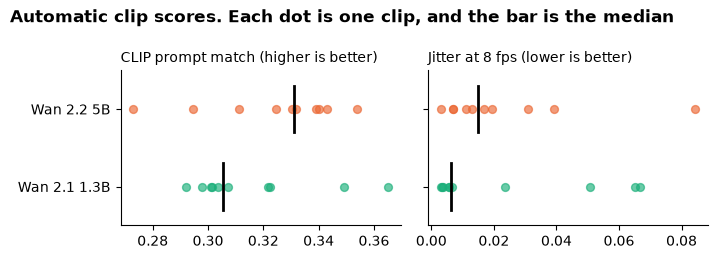

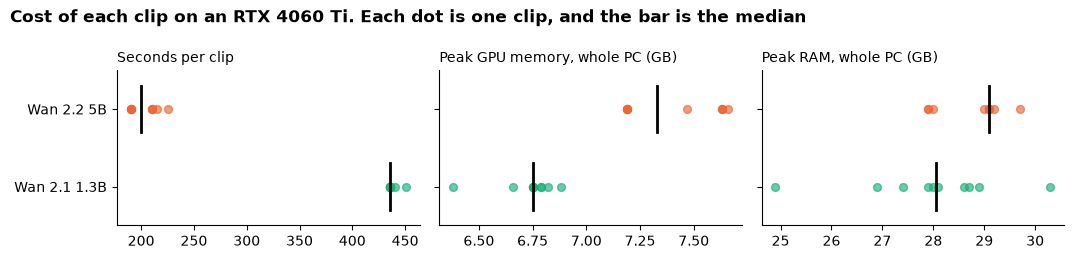

In [9]:
COLOURS, LABELS = {"wan22": "#eb6834", "wan21": "#1baf7a"}, {"wan22": "Wan 2.2 5B", "wan21": "Wan 2.1 1.3B"}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 200, "savefig.bbox": "tight"})
(RESULTS / "figures").mkdir(exist_ok=True)
charts = [("fig1_quality.png", "Automatic clip scores", [("prompt_match", "CLIP prompt match (higher is better)"), ("jitter_8fps", "Jitter at 8 fps (lower is better)")]),
          ("fig2_costs.png", "Cost of each clip on an RTX 4060 Ti", [("seconds", "Seconds per clip"), ("peak_gpu_gb", "Peak GPU memory, whole PC (GB)"), ("peak_ram_gb", "Peak RAM, whole PC (GB)")])]
for file, title, panels in charts:
    fig, axes = plt.subplots(1, len(panels), figsize=(3.6 * len(panels), 2.6), sharey=True)
    for axis, (column, heading) in zip(axes, panels):
        for row, model in enumerate(MODELS):
            values = done.loc[done["model"] == model, column].dropna()
            axis.scatter(values, [row] * len(values), color=COLOURS[model], s=32, alpha=0.65, zorder=3)
            axis.plot([values.median()] * 2, [row - 0.3, row + 0.3], color="black", linewidth=2, zorder=4)
        axis.set_title(heading, loc="left", fontsize=10)
    axes[0].set_yticks(range(len(MODELS)), [LABELS[m] for m in MODELS])
    axes[0].set_ylim(len(MODELS) - 0.5, -0.5)
    fig.suptitle(f"{title}. Each dot is one clip, and the bar is the median", x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout()
    fig.savefig(RESULTS / "figures" / file)
    plt.show()

## 7. Input-to-output demo

One sentence goes to each model, and the clip it returns is shown below. With `RUN_DEMO = False` this
shows the demo clips already saved in `results/demo`. Demo clips are not part of the evaluation.

In [10]:
demo = RESULTS / "demo"
print(f"INPUT: {DEMO_PROMPT}")
if RUN_DEMO:
    demo.mkdir(parents=True, exist_ok=True)
    server = comfyui()
    for model in MODELS:
        make_clip(server, model, "demo", DEMO_PROMPT, 11, demo)
for model in MODELS:
    path = demo / f"{model}_demo_11.mp4"
    print(f"OUTPUT from {LABELS[model]}:")
    display(Video(str(path), embed=True, width=640) if path.exists() else "No saved demo clip yet. Set RUN_DEMO = True with ComfyUI open.")

INPUT: A wide shot of a quiet harbour at sunset, small boats, gentle waves
OUTPUT from Wan 2.2 5B:


OUTPUT from Wan 2.1 1.3B:
